# Análisis de Ventas de una Cafetería

## Objetivo

Analizar el comportamiento de las ventas de una cafetería para identificar patrones en los ingresos, productos, categorías, tiendas y horarios, con el fin de obtener insights que puedan apoyar la toma de decisiones de negocio.

## Pregunta de negocio

> ¿Qué factores influyen en las ventas de la cafetería y qué oportunidades existen para mejorar su rendimiento?

## Dataset

El análisis utiliza el dataset **Coffee Shop Sales**, disponible en Maven Analytics Data Playground.

El conjunto de datos contiene información sobre las transacciones realizadas en tres establecimientos de una cafetería durante el período comprendido entre enero y junio de 2023.

## Metodología

El análisis seguirá las siguientes etapas:

1. Exploración y validación de los datos.
2. Limpieza y transformación.
3. Cálculo de métricas y KPIs.
4. Análisis exploratorio de productos, tiendas y períodos.
5. Visualización de los resultados.
6. Identificación de hallazgos e insights.
7. Recomendaciones de negocio.

# 1. Importación y carga de datos

## 1.1 Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
ruta = Path("../data/raw/Coffee Shop Sales.xlsx")
df = pd.read_excel(ruta)
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


# 2. Exploración y calidad de los datos

## 2.1 Dimensiones del dataset

In [3]:
df.shape

(149116, 11)

## 2.2 Información general de las variables

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[us]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  str           
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  str           
 9   product_type      149116 non-null  str           
 10  product_detail    149116 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(4), object(1), str(4)
memory usage: 19.8+ MB


## 2.3 Columnas del dataset

In [5]:
df.columns

Index(['transaction_id', 'transaction_date', 'transaction_time',
       'transaction_qty', 'store_id', 'store_location', 'product_id',
       'unit_price', 'product_category', 'product_type', 'product_detail'],
      dtype='str')

### Estructura del dataset

> El dataset contiene 149,116 registros y 11 variables. Las columnas incluyen información sobre transacciones, fechas, horarios, establecimientos, productos, cantidades y precios.

## 2.4 Valores faltantes

In [6]:
df.isna().sum()

transaction_id      0
transaction_date    0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64

> No se identificaron valores nulos en las variables analizadas.

## 2.5 Registros duplicados

In [7]:
df.duplicated().sum()

np.int64(0)

>No se identificaron valores duplicados en las variables analizadas.

## 2.6 Estadística descriptiva

In [8]:
df.describe()

,transaction_id,transaction_date,transaction_qty,store_id,product_id,unit_price
count,149116.000000,149116,149116.000000,149116.000000,149116.000000,149116.000000
mean,74737.371872,2023-04-15 11:50:32.173609,1.438276,5.342063,47.918607,3.382219
min,1.000000,2023-01-01 00:00:00,1.000000,3.000000,1.000000,0.800000
25%,37335.750000,2023-03-06 00:00:00,1.000000,3.000000,33.000000,2.500000
50%,74727.500000,2023-04-24 00:00:00,1.000000,5.000000,47.000000,3.000000
75%,112094.250000,2023-05-30 00:00:00,2.000000,8.000000,60.000000,3.750000
max,149456.000000,2023-06-30 00:00:00,8.000000,8.000000,87.000000,45.000000
std,43153.600016,NaN,0.542509,2.074241,17.930020,2.658723


> La estadística descriptiva permite revisar la distribución de variables numéricas como cantidad vendida, precio unitario e identificadores de productos y tiendas.

In [9]:
df[df["unit_price"] == 45].head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
5182,5212,2023-01-10,09:20:43,1,5,Lower Manhattan,8,45.0,Coffee beans,Premium Beans,Civet Cat
5874,5904,2023-01-11,11:24:31,1,8,Hell's Kitchen,8,45.0,Coffee beans,Premium Beans,Civet Cat
5939,5969,2023-01-11,13:53:09,1,5,Lower Manhattan,8,45.0,Coffee beans,Premium Beans,Civet Cat
7616,7646,2023-01-14,10:57:38,1,8,Hell's Kitchen,8,45.0,Coffee beans,Premium Beans,Civet Cat
8443,8473,2023-01-15,18:18:51,1,3,Astoria,8,45.0,Coffee beans,Premium Beans,Civet Cat


In [10]:
df.loc[
    df["unit_price"] == 45, ["product_id", "product_type", "product_detail"]
].head()

,product_id,product_type,product_detail
5182,8,Premium Beans,Civet Cat
5874,8,Premium Beans,Civet Cat
5939,8,Premium Beans,Civet Cat
7616,8,Premium Beans,Civet Cat
8443,8,Premium Beans,Civet Cat


In [11]:
total_filas = (df["unit_price"] == 45).sum()
total_filas

np.int64(190)

In [12]:
ingreso_total_generado = (((df["unit_price"] == 45) * df["transaction_qty"]) * 45).sum()
ingreso_total_generado

np.int64(11700)

# 3. Preparación y transformación de los datos

Para realizar el análisis se trabajará sobre una copia del dataset original, manteniendo los datos de origen sin modificaciones.

In [13]:
df_new = df.copy()

## 3.1 Cálculo de ingresos

Se calcula el ingreso generado por cada registro multiplicando el precio unitario por la cantidad de unidades vendidas.

$$
Revenue = Unit\ Price \times Transaction\ Quantity
$$

In [14]:
df_new["revenue"] = df_new["unit_price"] * df_new["transaction_qty"]
df_new["revenue"]

0         6.00
1         6.20
2         9.00
3         2.00
4         6.20
          ... 
149111    5.00
149112    6.00
149113    3.00
149114    3.75
149115    1.60
Name: revenue, Length: 149116, dtype: float64

In [15]:
df_new["revenue"].sum()

np.float64(698812.3300000001)

In [16]:
df_new[df_new["unit_price"] == df_new["unit_price"].max()][
    ["product_type", "product_detail", "unit_price"]
]

,product_type,product_detail,unit_price
5182,Premium Beans,Civet Cat,45.0
5874,Premium Beans,Civet Cat,45.0
5939,Premium Beans,Civet Cat,45.0
7616,Premium Beans,Civet Cat,45.0
8443,Premium Beans,Civet Cat,45.0
...,...,...,...
144743,Premium Beans,Civet Cat,45.0
145411,Premium Beans,Civet Cat,45.0
148573,Premium Beans,Civet Cat,45.0
148702,Premium Beans,Civet Cat,45.0


In [17]:
df_new.groupby('product_type')['transaction_qty'].sum().sort_values(ascending=False)

product_type
Brewed Chai tea          26250
Gourmet brewed coffee    25973
Barista Espresso         24943
Brewed Black tea         17462
Hot chocolate            17457
Brewed herbal tea        17328
Organic brewed coffee    13012
Drip coffee              12891
Premium brewed coffee    12431
Scone                    10465
Brewed Green tea          8697
Regular syrup             7606
Pastry                    6961
Biscotti                  5788
Sugar free syrup          2905
Housewares                 555
Chai tea                   443
Organic Beans              420
Premium Beans              406
Gourmet Beans              366
Espresso Beans             319
Herbal tea                 305
Black tea                  303
Drinking Chocolate         266
Clothing                   221
Organic Chocolate          221
House blend Beans          183
Green tea                  159
Green beans                134
Name: transaction_qty, dtype: int64

### producto que mayor ingresos genera

In [18]:
top_ingresos = df_new.groupby("product_type")["revenue"].sum().sort_values(ascending=False)
print(top_ingresos.head(1))

product_type
Barista Espresso    91406.2
Name: revenue, dtype: float64


### categoria que mayor ingresos genera

In [19]:
top_ingresos_categoria = df_new.groupby("product_category")["revenue"].sum().sort_values(ascending=False)
top_ingresos_categoria.head(1)

product_category
Coffee    269952.45
Name: revenue, dtype: float64

###  tienda que genera mas ingresos

In [20]:
top_ingresos_tienda = df_new.groupby("store_location")["revenue"].sum().sort_values(ascending=False)
top_ingresos_tienda.head(1)

store_location
Hell's Kitchen    236511.17
Name: revenue, dtype: float64

In [21]:
df_new["store_location"].unique()

<ArrowStringArray>
['Lower Manhattan', 'Hell's Kitchen', 'Astoria']
Length: 3, dtype: str

### periodo de analisis

In [22]:
df_new["transaction_date"]

0        2023-01-01
1        2023-01-01
2        2023-01-01
3        2023-01-01
4        2023-01-01
            ...    
149111   2023-06-30
149112   2023-06-30
149113   2023-06-30
149114   2023-06-30
149115   2023-06-30
Name: transaction_date, Length: 149116, dtype: datetime64[us]

## 3.2 Creación de variables temporales

Para facilitar el análisis temporal se crean variables derivadas a partir de la fecha y hora de cada transacción.

### Día de la semana con mayores ingresos

In [23]:
df_new["day_of_week"] = df_new["transaction_date"].dt.day_name()
top_dias_ingresos = df_new.groupby("day_of_week")["revenue"].sum().sort_values(ascending=False)
top_dias_ingresos.head(1)

day_of_week
Monday    101677.28
Name: revenue, dtype: float64

In [24]:
df_new['anio_mes'] = df_new['transaction_date'].dt.to_period('M')
ingresos_por_mes = df_new.groupby('anio_mes')["revenue"].sum().reset_index()
ingresos_por_mes

,anio_mes,revenue
0,2023-01,81677.74
1,2023-02,76145.19
2,2023-03,98834.68
3,2023-04,118941.08
4,2023-05,156727.76
5,2023-06,166485.88


### Hora de la transacción

Se extrae la hora de cada transacción para identificar los períodos del día con mayor actividad comercial.

In [25]:
df_new["transaction_time"] = pd.to_datetime(df_new["transaction_time"], format="%H:%M:%S")
df_new["hour_of_day"] = df_new["transaction_time"].dt.hour

top_horas_ventas = df_new.groupby("hour_of_day")["revenue"].sum().sort_values(ascending=False)
top_horas_ventas.head(1)

hour_of_day
10    88673.39
Name: revenue, dtype: float64

# 4. KPIs de ventas

Los KPIs (Key Performance Indicators) son métricas utilizadas para evaluar aspectos relevantes del desempeño de un negocio.

En este análisis se utilizarán indicadores relacionados con los ingresos, las unidades vendidas, las transacciones y el valor promedio de las ventas.

In [26]:
df_new["revenue"].sum()

np.float64(698812.3300000001)

In [27]:
df_new["transaction_id"].nunique()

149116

### transacciones promedio

In [28]:
df_new["transaction_qty"].mean()

np.float64(1.438276241315486)

### ingresos promedios por cada transaccion

In [29]:

df_new["revenue"].mean()

np.float64(4.6863671906435265)

# 5. Análisis exploratorio

### transacciones por tienda

In [30]:
ventas_tienda = df_new.groupby("store_location")["transaction_qty"].sum().sort_values(ascending=False)
ventas_tienda

store_location
Lower Manhattan    71742
Hell's Kitchen     71737
Astoria            70991
Name: transaction_qty, dtype: int64

### ingreso vs tienda

In [31]:
info_tiendas = pd.DataFrame([ventas_tienda, top_ingresos_tienda])
info_tiendas

store_location,Lower Manhattan,Hell's Kitchen,Astoria
transaction_qty,71742.00,71737.00,70991.00
revenue,230057.25,236511.17,232243.91


## 5.1 Análisis de productos

### precio promedio de cada producto

In [32]:
products_unitprice = df_new.groupby("product_category")["unit_price"].mean().sort_values(ascending=False)
products_unitprice

product_category
Coffee beans          21.018397
Branded               17.720214
Loose Tea              9.267438
Packaged Chocolate     9.050595
Drinking Chocolate     4.148827
Bakery                 3.551682
Coffee                 3.023646
Tea                    2.817121
Flavours               0.800000
Name: unit_price, dtype: float64

### Los 10 productos que más ingresos generan

In [33]:
productos_mayor_ingreso= df_new.groupby("product_type")["revenue"].sum().sort_values(ascending=False).head(10)
productos_mayor_ingreso

product_type
Barista Espresso         91406.20
Brewed Chai tea          77081.95
Hot chocolate            72416.00
Gourmet brewed coffee    70034.60
Brewed Black tea         47932.00
Brewed herbal tea        47539.50
Premium brewed coffee    38781.15
Organic brewed coffee    37746.50
Scone                    36866.12
Drip coffee              31984.00
Name: revenue, dtype: float64

### Producto más vendido vs. producto que más factura

In [34]:
top_vendidos= df_new.groupby('product_type')['transaction_qty'].sum().sort_values(ascending=False)
print("".center(50, "-"))
print("producto mas vendido".center(50, "-"))
print(top_vendidos.head(1))
print("".center(50, "-"))
print("producto que mas ingresos genera".center(50, "-"))
print(top_ingresos.head(1))

top_vendidos_ingresos = pd.DataFrame({
    'revenue': top_ingresos.head(10),
    'transaction_qty': top_vendidos.head(10)
})

top_vendidos_ingresos_ordenado = top_vendidos_ingresos.sort_values(by=['revenue', 'transaction_qty'], ascending=False)

print("".center(50, "-"))
print(top_vendidos_ingresos_ordenado)

--------------------------------------------------
---------------producto mas vendido---------------
product_type
Brewed Chai tea    26250
Name: transaction_qty, dtype: int64
--------------------------------------------------
---------producto que mas ingresos genera---------
product_type
Barista Espresso    91406.2
Name: revenue, dtype: float64
--------------------------------------------------
                        revenue  transaction_qty
product_type                                    
Barista Espresso       91406.20            24943
Brewed Chai tea        77081.95            26250
Hot chocolate          72416.00            17457
Gourmet brewed coffee  70034.60            25973
Brewed Black tea       47932.00            17462
Brewed herbal tea      47539.50            17328
Premium brewed coffee  38781.15            12431
Organic brewed coffee  37746.50            13012
Scone                  36866.12            10465
Drip coffee            31984.00            12891


El producto con mayor volumen de ventas es **Brewed Chai tea**, con 26,250 unidades, mientras que **Barista Espresso** es el producto que genera mayores ingresos, con aproximadamente 91,406.

Esto demuestra que el producto con mayor volumen de ventas no necesariamente es el que genera mayores ingresos.

In [35]:
productos_interes = ["Barista Espresso", "Brewed Chai tea"]
df_filtrado = df_new[df_new["product_type"].isin(productos_interes)][["product_type", "unit_price"]]
df_promedio = df_filtrado.groupby("product_type")["unit_price"].mean().reset_index()
df_promedio

,product_type,unit_price
0,Barista Espresso,3.655200
1,Brewed Chai tea,2.936993


In [36]:
precio_promedio_productos = df_new.groupby("product_type")["unit_price"].mean().sort_values(ascending=False).reset_index()
precio_promedio_productos

,product_type,unit_price
0,Premium Beans,34.028274
1,Clothing,27.886878
2,Organic Beans,20.287952
3,Gourmet Beans,18.573770
4,House blend Beans,18.000000
5,Espresso Beans,17.430251
6,Housewares,13.448669
7,Drinking Chocolate,10.255789
8,Green beans,10.000000
9,Chai tea,9.709368


### Evolución mensual de los ingresos

In [37]:
df_new['anio_mes'] = df_new['transaction_date'].dt.to_period('M')
ingresos_por_mes = df_new.groupby('anio_mes')["revenue"].sum().reset_index()
ingresos_por_mes

,anio_mes,revenue
0,2023-01,81677.74
1,2023-02,76145.19
2,2023-03,98834.68
3,2023-04,118941.08
4,2023-05,156727.76
5,2023-06,166485.88


la evolucion mensual de los ingresos fue creciente a excepcion del segundo mes 

In [38]:
df_new.groupby('anio_mes')["transaction_id"].nunique().sort_values(ascending=False).head(1)

anio_mes
2023-06    35352
Freq: M, Name: transaction_id, dtype: int64

el mes con mayores transacciones fue junio y tambien fue el mes con mayor ingreso

### Hora de mayor actividad y a que hora se realizan la mayoria de las transacciones

In [39]:
print(df_new.groupby('hour_of_day')["transaction_id"].nunique().sort_values(ascending=False).reset_index().head(1))
print(top_horas_ventas.head(1))

   hour_of_day  transaction_id
0           10           18545
hour_of_day
10    88673.39
Name: revenue, dtype: float64


Las 10:00 es la hora con mayor número de transacciones registradas.

### comportamiento de mayor hora de actividad en tiendas 

In [40]:
horario_mayor_actividad = (
    df_new.groupby(['store_location', 'hour_of_day'])['transaction_id']
    .nunique()
    .reset_index(name='transaction_count')
)
horario_mayor_actividad
horario_mayor_actividad.loc[
    horario_mayor_actividad.groupby('store_location')['transaction_count'].idxmax()
]

,store_location,hour_of_day,transaction_count
3,Astoria,10,5291
17,Hell's Kitchen,10,6957
32,Lower Manhattan,10,6297


Las 10:00 es la hora de mayor actividad en cada una de las tres tiendas.

### categoria de producto que genera mas ingresos por tienda

## 5.2 Análisis por tiendas

### ventas de cada tienda por unidad 

In [41]:
ventas_tienda = df_new.groupby("store_location")["transaction_qty"].sum().sort_values(ascending=False)
ventas_tienda

store_location
Lower Manhattan    71742
Hell's Kitchen     71737
Astoria            70991
Name: transaction_qty, dtype: int64

### ingresos por unidad de cada tienda

In [42]:
info_tiendas = pd.DataFrame([ventas_tienda, top_ingresos_tienda])
info_tiendas

store_location,Lower Manhattan,Hell's Kitchen,Astoria
transaction_qty,71742.00,71737.00,70991.00
revenue,230057.25,236511.17,232243.91


In [43]:
print(df_new.groupby(['store_location', 'product_category'])['revenue'].sum().sort_values(ascending=False))

store_location   product_category  
Hell's Kitchen   Coffee                91222.65
Astoria          Coffee                89744.30
Lower Manhattan  Coffee                88985.50
Astoria          Tea                   67839.90
Hell's Kitchen   Tea                   64701.30
Lower Manhattan  Tea                   63864.75
                 Bakery                28328.94
Hell's Kitchen   Bakery                27386.95
Astoria          Bakery                26599.75
                 Drinking Chocolate    26335.25
Hell's Kitchen   Drinking Chocolate    23586.25
Lower Manhattan  Drinking Chocolate    22494.50
Hell's Kitchen   Coffee beans          18635.10
Lower Manhattan  Coffee beans          11230.95
Astoria          Coffee beans          10219.20
Lower Manhattan  Branded                6208.00
Astoria          Branded                5457.00
Hell's Kitchen   Loose Tea              4461.35
Lower Manhattan  Flavours               3767.20
                 Loose Tea              3558.25
Asto

la categoria de producto que mas genera por tienda es el coffee


In [44]:
df_new['transaction_id'].info()

<class 'pandas.Series'>
RangeIndex: 149116 entries, 0 to 149115
Series name: transaction_id
Non-Null Count   Dtype
--------------   -----
149116 non-null  int64
dtypes: int64(1)
memory usage: 1.1 MB


### principales generadores de ingresos de las cafeterías

In [45]:
top10_revenue = (df_new.groupby(['product_type', 'product_category'])[['revenue', 'transaction_qty']]
    .sum().sort_values(by= ['revenue', 'transaction_qty'], ascending=False).head(10))
print(top10_revenue)
# top_vendidos_ingresos_ordenado

                                           revenue  transaction_qty
product_type          product_category                             
Barista Espresso      Coffee              91406.20            24943
Brewed Chai tea       Tea                 77081.95            26250
Hot chocolate         Drinking Chocolate  72416.00            17457
Gourmet brewed coffee Coffee              70034.60            25973
Brewed Black tea      Tea                 47932.00            17462
Brewed herbal tea     Tea                 47539.50            17328
Premium brewed coffee Coffee              38781.15            12431
Organic brewed coffee Coffee              37746.50            13012
Scone                 Bakery              36866.12            10465
Drip coffee           Coffee              31984.00            12891


###  porcentaje de los ingresos totales que representa el Top 10 de productos

In [46]:
revenue_total = df_new['revenue'].sum()
revenue_total
revenue_total_10 = top10_revenue.sum()
revenue_total_10['revenue']
porcentaje_ingresos_totales = (revenue_total_10['revenue']/revenue_total) * 100
porcentaje_ingresos_totales

np.float64(78.96083058523023)

> el top 10 de los productos representa e 78.96% de los ingresos totales de las cafeterias.

In [47]:
resumen_productos = (
    df_new.groupby('product_type')
    .agg({
        'unit_price': 'mean',        # Precio promedio
        'transaction_qty': 'sum',    # Unidades totales vendidas
    })
    .sort_values(by=['unit_price'], ascending=False)
)

print(resumen_productos)

                       unit_price  transaction_qty
product_type                                      
Premium Beans           34.028274              406
Clothing                27.886878              221
Organic Beans           20.287952              420
Gourmet Beans           18.573770              366
House blend Beans       18.000000              183
Espresso Beans          17.430251              319
Housewares              13.448669              555
Drinking Chocolate      10.255789              266
Green beans             10.000000              134
Chai tea                 9.709368              443
Green tea                9.250000              159
Black tea                8.950000              303
Herbal tea               8.950000              305
Organic Chocolate        7.600000              221
Hot chocolate            4.148827            17457
Pastry                   3.685979             6961
Barista Espresso         3.655200            24943
Scone                    3.5346

> Los datos muestran un patrón en el que los productos con mayor precio promedio presentan, en general, menores volúmenes de venta.

## 5.3 Análisis temporal

### Día de la semana con mayores ingresos

In [48]:
df_new["day_of_week"] = df_new["transaction_date"].dt.day_name()
top_dias_ingresos = df_new.groupby("day_of_week")["revenue"].sum().sort_values(ascending=False)
top_dias_ingresos.head(1)

day_of_week
Monday    101677.28
Name: revenue, dtype: float64

### ingresos por mes

In [49]:
df_new['anio_mes'] = df_new['transaction_date'].dt.to_period('M')
ingresos_por_mes = df_new.groupby('anio_mes')["revenue"].sum().reset_index()
ingresos_por_mes

,anio_mes,revenue
0,2023-01,81677.74
1,2023-02,76145.19
2,2023-03,98834.68
3,2023-04,118941.08
4,2023-05,156727.76
5,2023-06,166485.88


In [50]:
df_new.groupby('anio_mes')["transaction_id"].nunique().sort_values(ascending=False).head(1)

anio_mes
2023-06    35352
Freq: M, Name: transaction_id, dtype: int64

> Junio fue el mes con mayor cantidad de transacciones y también presentó los mayores ingresos del período analizado.

In [51]:
print(df_new.groupby('hour_of_day')["transaction_id"].nunique().sort_values(ascending=False).reset_index().head(1))
print(top_horas_ventas.head(1))

   hour_of_day  transaction_id
0           10           18545
hour_of_day
10    88673.39
Name: revenue, dtype: float64


In [52]:
horario_mayor_actividad = (
    df_new.groupby(['store_location', 'hour_of_day'])['transaction_id']
    .nunique()
    .reset_index(name='transaction_count')
)
horario_mayor_actividad
horario_mayor_actividad.loc[
    horario_mayor_actividad.groupby('store_location')['transaction_count'].idxmax()
]

,store_location,hour_of_day,transaction_count
3,Astoria,10,5291
17,Hell's Kitchen,10,6957
32,Lower Manhattan,10,6297


> Las 10:00 es la hora de mayor actividad registrada en las tres tiendas.

## 5.4 Relación entre precio y volumen

In [53]:
resumen_productos = (
    df_new.groupby("product_type")
    .agg({
        "unit_price": "mean",
        "transaction_qty": "sum"
    })
    .sort_values(
        by="unit_price",
        ascending=False
    )
)

resumen_productos

,unit_price,transaction_qty
product_type,,
Premium Beans,34.028274,406
Clothing,27.886878,221
Organic Beans,20.287952,420
Gourmet Beans,18.573770,366
House blend Beans,18.000000,183
Espresso Beans,17.430251,319
Housewares,13.448669,555
Drinking Chocolate,10.255789,266
Green beans,10.000000,134


In [54]:
type(resumen_productos)
corr_precio_unidades = resumen_productos['unit_price'].corr(resumen_productos['transaction_qty'])
corr_precio_unidades

np.float64(-0.5867932490454765)

Se obtuvo un coeficiente de correlación de **-0.5868**, lo que indica una relación negativa moderada entre el precio promedio y las unidades vendidas a nivel de producto.

En este conjunto de datos, los productos con mayor precio promedio tienden a presentar menores volúmenes de venta. Sin embargo, esta relación representa una asociación y no permite establecer que el precio sea la causa de las diferencias observadas.

# 6. Visualizaciones

## 6.1 Evolución mensual de ingresos

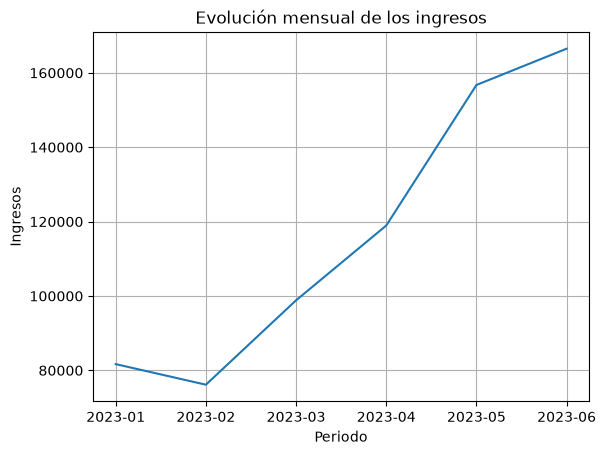

In [55]:
x = ingresos_por_mes["anio_mes"].astype(str)
y = ingresos_por_mes["revenue"]

fig, ax = plt.subplots()

ax.plot(x, y)

ax.set(
    xlabel="Periodo",
    ylabel="Ingresos",
    title="Evolución mensual de los ingresos"
)

ax.grid()
plt.show()

Los ingresos presentan una tendencia general creciente durante el período analizado, aunque se observa una disminución en febrero.

## 6.2 Ingresos por categoría

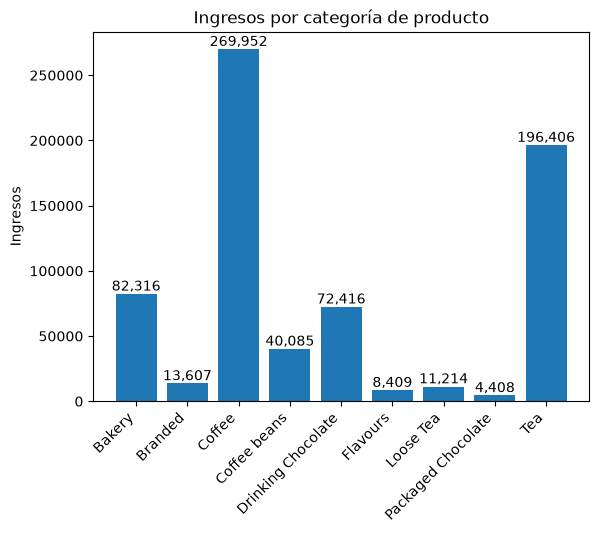

In [56]:
fig, ax = plt.subplots()

revenue_category = (
    df_new.groupby("product_category")["revenue"]
    .sum()
    .reset_index()
)

bar_container = ax.bar(
    revenue_category["product_category"],
    revenue_category["revenue"]
)

ax.set(
    ylabel="Ingresos",
    title="Ingresos por categoría de producto"
)

ax.bar_label(bar_container, fmt="{:,.0f}")

plt.xticks(rotation=45, ha="right")
plt.show()

Las categorías Coffee y Tea presentan los mayores ingresos entre las categorías analizadas.

In [57]:
ventas_tiendadf["transaction_qty"] = pd.to_numeric(ventas_tiendadf["transaction_qty"], errors='coerce')
# print(ventas_tiendadf)

df_agrupado = ventas_tiendadf.groupby("store_location", as_index=False)["transaction_qty"].sum()
# print(df_agrupado)

ax = sns.barplot(
    data=df_agrupado, 
    x="store_location", 
    y="transaction_qty", 
    hue="store_location", 
    legend=False, 
    errorbar=None
)

for p in ax.patches:
    altura = p.get_height()
    if pd.isna(altura):
        continue
    ax.annotate(
        f"{int(altura)}",
        (p.get_x() + p.get_width() / 2., altura),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points'
    )

plt.title("Transacciones por Tienda", fontsize=14, fontweight='bold')
plt.xlabel("Ubicación de la Tienda", fontsize=11)
plt.ylabel("Cantidad de Transacciones", fontsize=11)

plt.tight_layout()

plt.xticks(rotation=45)
plt.show()

NameError: name 'ventas_tiendadf' is not defined

la cantidad de transacciones por tienda tienen un margen de diferencia minimo pero la mayoria de transacciones ocurrio en lower manhattan

In [ ]:
type(top_ingresos_tienda)
top_ingresos_tiendadf = top_ingresos_tienda.reset_index()
print(top_ingresos_tiendadf)

ax = sns.barplot(
    data=top_ingresos_tiendadf, 
    x="store_location", 
    y="revenue", 
    hue="store_location", 
    legend=False, 
    errorbar=None
)


for p in ax.patches:
    altura = p.get_height()
    if pd.isna(altura):
        continue
    ax.annotate(
        f"{int(altura)}",
        (p.get_x() + p.get_width() / 2., altura),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points'
    )

plt.title("Total de Ingresos por Tienda", fontsize=14, fontweight='bold')
plt.xlabel("Ubicación de la Tienda", fontsize=11)
plt.ylabel("Cantidad de Ingresos", fontsize=11)

plt.tight_layout()

plt.xticks(rotation=45)
plt.show()

No hay mucha diferencia en los ingresos, hells kitchen es la que mayor ingresos tiene.

In [ ]:
products_unitpricedf = products_unitprice.reset_index()
print(products_unitpricedf)

ax = sns.barplot(
    data=products_unitpricedf, 
    x="product_category", 
    y="unit_price", 
    hue="product_category", 
    legend=False, 
    errorbar=None
)


for p in ax.patches:
    altura = p.get_height()
    if pd.isna(altura):
        continue
    ax.annotate(
        f"{altura:.2f}", 
        (p.get_x() + p.get_width() / 2., altura),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points'
    )

plt.title("Precio promedio unitario de los productos segun su categoría", fontsize=14, fontweight='bold')
plt.xlabel("Producto", fontsize=11)
plt.ylabel("Precio Unitario", fontsize=11)

plt.tight_layout()

plt.xticks(rotation=45)
plt.show()

Precio promedio de los productos segun su categoria.

In [ ]:
productos_mayor_ingresodf = productos_mayor_ingreso.reset_index()
print(productos_mayor_ingresodf)


ax = sns.barplot(
    data=productos_mayor_ingresodf, 
    x="product_type", 
    y="revenue", 
    hue="product_type", 
    legend=False, 
    errorbar=None,
    
)

#
for p in ax.patches:
    altura = p.get_height()
    if pd.isna(altura):
        continue
    ax.annotate(
        f"{int(altura)}",
        (p.get_x() + p.get_width() / 2., altura),
        ha='center',
        va='bottom',
        xytext=(0, 3),
        textcoords='offset points'
    )

plt.title("Ingresos totales por tipo de productos", fontsize=14, fontweight='bold')
plt.xlabel("Productos", fontsize=11)
plt.ylabel("Ingresos", fontsize=11)

plt.tight_layout()

plt.xticks(rotation=90)
plt.show()

El producto que mayor ingreso genera es Barista Espresso con un total de 91406 de ingresos

# 7. Insights y recomendaciones de negocio

## 7.1 Principales hallazgos

- El **Top 10 de productos representa aproximadamente el 78.96% de los ingresos totales**, lo que evidencia una alta concentración de los ingresos en un grupo reducido de productos.

- Las categorías **Coffee y Tea concentran los mayores ingresos** entre las categorías de productos analizadas.

- **Barista Espresso** es el producto que genera mayores ingresos, con aproximadamente **91,406**, mientras que **Brewed Chai tea** es el producto con mayor cantidad de unidades vendidas, con **26,250 unidades**. Esto demuestra que el producto más vendido en volumen no necesariamente es el que genera mayores ingresos.

- Los ingresos presentan una **tendencia general creciente durante el período analizado**, aunque se observa una disminución durante el segundo mes.

- Se identificó una **relación negativa moderada** entre el precio promedio y las unidades vendidas (`r = -0.5868`). En este conjunto de datos, los productos con mayor precio promedio tienden a registrar menores volúmenes de venta. Sin embargo, esta relación no permite establecer que el precio sea la causa de este comportamiento.

## 7.2 Insights de negocio

Los ingresos de la cafetería están altamente concentrados en un grupo reducido de productos, ya que los 10 productos principales representan aproximadamente el **78.96% de los ingresos totales**. Esto indica que estos productos tienen una participación importante en el desempeño económico observado durante el período analizado.

Además, las categorías **Coffee y Tea** presentan los mayores niveles de ingresos, por lo que representan segmentos relevantes para analizar el comportamiento comercial de la cafetería.

La diferencia entre los productos con mayor volumen de ventas y los productos con mayor generación de ingresos también muestra que **vender más unidades no necesariamente implica generar más ingresos**. Por esta razón, ambas métricas deben analizarse conjuntamente.

## 7.3 Recomendaciones

- **Monitorear la disponibilidad** de los productos con mayor contribución a los ingresos para reducir el riesgo de interrupciones en las ventas.

- **Analizar oportunidades comerciales** dentro de las categorías Coffee y Tea, debido a que concentran los mayores ingresos entre las categorías analizadas.

- Evaluar estrategias diferenciadas para productos con **alto volumen de ventas** y productos con **alta generación de ingresos**, midiendo posteriormente su impacto en las ventas.

- Analizar el comportamiento de los productos de mayor precio para determinar si existen oportunidades de ajustar su estrategia comercial, teniendo en cuenta que la relación observada entre precio y volumen de ventas no implica causalidad.

## 7.4 Limitaciones del análisis

- El dataset comprende únicamente el período entre **enero y junio de 2023**, por lo que no es suficiente para analizar el comportamiento de un año completo o determinar patrones de estacionalidad anual.

- El dataset no contiene información sobre **costos**, por lo que el análisis permite estudiar ingresos, pero no determinar cuáles productos son más rentables.

- No se dispone de información detallada sobre los **clientes**, por lo que no es posible analizar preferencias individuales, frecuencia de compra o retención.

- No se cuenta con información sobre **inventario, promociones, clima, eventos o factores externos**, por lo que no es posible determinar con certeza las causas de los cambios observados en las ventas.

- Las relaciones encontradas entre variables, como precio y unidades vendidas, representan asociaciones dentro de los datos y **no permiten establecer relaciones causales**.

## 7.5 Conclusión

El análisis muestra que los ingresos de la cafetería se encuentran concentrados principalmente en un grupo reducido de productos, con una participación destacada de las categorías **Coffee y Tea**. También se observa que los productos con mayor volumen de ventas no necesariamente son los que generan mayores ingresos.

En términos de negocio, estos resultados permiten identificar los productos y categorías que tienen mayor participación en los ingresos y establecer líneas de análisis para mejorar su seguimiento. Sin embargo, para tomar decisiones más precisas sería necesario incorporar información adicional, como costos, inventario, promociones y comportamiento de los clientes.

In [ ]:
df_new

In [ ]:
df_new.to_csv("../data/processed/coffee_shop_sales_processed.csv", index=False)